# BÀI THỰC HÀNH 2: MẠNG NEURAL TÍCH CHẬP

<b>Hướng dẫn nộp bài:</b> Các bạn commit và push code lên github, sử dụng file txt đặt tên theo cú pháp <MSSV>.txt chứa đường link dẫn đến github của bài thực hành và nộp file txt này tên courses..

Bộ dữ liệu sử dụng: [VinaFood21 dataset](https://arxiv.org/abs/2108.02929).

Link download: https://drive.google.com/file/d/1UpZOf0XlwvB4rKpyZ35iwTA8oWHqDBbR/view?usp=share_link.

In [1]:
from pathlib import Path

DATA_ROOT = Path("VinaFood21")
IMG_SIZE = 64
BATCH = 32
SEED = 42

HAS_DATA = (DATA_ROOT / "train").is_dir()
print("Tìm thấy dữ liệu:", HAS_DATA, "-", DATA_ROOT.resolve())

Tìm thấy dữ liệu: True - D:\Main class UIT\Năm 3\DS201_DeepLearning\TH\TH Buoi2\VinaFood21


### Bài 1: Xây dựng mô hình LeNet. Huấn luyện và đánh giá mô hình LeNet trên 4 độ đo precision, recall và F1-macro (sử dụng Adam làm optimizer).

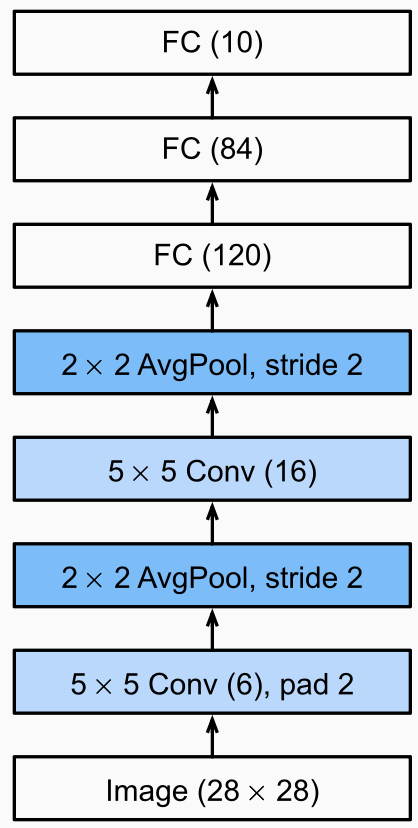

In [2]:
from torchvision import transforms

MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

# Xử lý ảnh dùng để học
train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(
        brightness=0.2, contrast=0.2, saturation=0.2
    ),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

# Xử lý ảnh dùng để đánh giá
eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

print("Đã dựng train_tf và eval_tf.")

Đã dựng train_tf và eval_tf.


In [3]:
import torch
from torchvision import datasets
from torch.utils.data import random_split, Subset


train_source = datasets.ImageFolder(
    DATA_ROOT / "train", transform=train_tf
)
val_source = datasets.ImageFolder(
    DATA_ROOT / "train", transform=eval_tf
)


n_val = int(len(train_source) * 0.1)
n_train = len(train_source) - n_val

train_ds, val_part = random_split(
    train_source,
    [n_train, n_val],
    generator=torch.Generator().manual_seed(SEED)
)


val_ds = Subset(val_source, val_part.indices)

CLASSES = train_source.classes

print("Số lớp:", len(CLASSES))
print("Số ảnh train:", len(train_ds))
print("Số ảnh validation:", len(val_ds))

Số lớp: 21
Số ảnh train: 9040
Số ảnh validation: 1004


In [4]:
from torch.utils.data import DataLoader

train_dl = DataLoader(
    train_ds, batch_size=BATCH, shuffle=True, num_workers=2
)

val_dl = DataLoader(
    val_ds, batch_size=BATCH, shuffle=False, num_workers=2
)

CLASSES = train_source.classes

print("số lớp      :", len(CLASSES))
print("số ảnh train:", len(train_ds))
print("thứ tự lớp  :", CLASSES[:5], "...")

số lớp      : 21
số ảnh train: 9040
thứ tự lớp  : ['banh-can', 'banh-hoi', 'banh-mi-chao', 'banh-tet', 'banh-trang-tron'] ...


In [5]:
anh, nhan = train_ds[0]

# Lấy một nhóm ảnh và nhãn từ DataLoader
xb, yb = next(iter(train_dl))

print("Một ảnh:", tuple(anh.shape))
print("Một batch ảnh:", tuple(xb.shape))
print("Một batch nhãn:", tuple(yb.shape))

Một ảnh: (3, 64, 64)
Một batch ảnh: (32, 3, 64, 64)
Một batch nhãn: (32,)


In [6]:
def show(label, t):
    print(f"{label:<28} {tuple(t.shape)}")


anh = torch.rand(3, 224, 224)
batch = torch.rand(32, 3, 224, 224)

show("một ảnh (C, H, W)", anh)
show("một batch (N, C, H, W)", batch)

print("N =", batch.shape[0])
print("C =", batch.shape[1])
print("H =", batch.shape[2])
print("W =", batch.shape[3])

một ảnh (C, H, W)            (3, 224, 224)
một batch (N, C, H, W)       (32, 3, 224, 224)
N = 32
C = 3
H = 224
W = 224


In [7]:
for h, w in [(256, 256), (224, 224)]:
    n_in = h * w * 3
    n_hidden = 1000
    params = n_in * n_hidden          # bỏ qua bias
    print(f"{h}x{w}x3 -> {n_in:>8,} input x {n_hidden:,} neuron = {params:>14,} tham số")

assert 256 * 256 * 3 * 1000 == 196_608_000
assert 224 * 224 * 3 * 1000 == 150_528_000

256x256x3 ->  196,608 input x 1,000 neuron =    196,608,000 tham số
224x224x3 ->  150,528 input x 1,000 neuron =    150,528,000 tham số


In [8]:
anh = torch.tensor([[4., 9., 2., 5., 8., 3.],
                    [5., 6., 2., 4., 0., 3.],
                    [2., 4., 5., 4., 5., 2.],
                    [5., 6., 5., 4., 7., 8.],
                    [5., 7., 7., 9., 2., 1.],
                    [5., 8., 5., 3., 8., 4.]]).reshape(1, 1, 6, 6)

kernel = torch.tensor([[1., 0., -1.],
                       [1., 0., -1.],
                       [1., 0., -1.]]).reshape(1, 1, 3, 3)

show("ảnh vào", anh)
show("kernel", kernel)

ảnh vào                      (1, 1, 6, 6)
kernel                       (1, 1, 3, 3)


In [9]:
import torch.nn.functional as F

out = F.conv2d(anh, kernel, stride=1, padding=0)

show("output", out)
print("\noutput:\n", out[0, 0])
print("\nô đầu tiên =", out[0, 0, 0, 0].item())
print("ô thứ hai  =", out[0, 0, 0, 1].item())

assert out.shape == (1, 1, 4, 4)
assert out[0, 0, 0, 0].item() == 2.0
assert out[0, 0, 0, 1].item() == 6.0

output                       (1, 1, 4, 4)

output:
 tensor([[ 2.,  6., -4.,  5.],
        [ 0.,  4.,  0., -1.],
        [-5.,  0.,  3.,  6.],
        [-2.,  5.,  0.,  3.]])

ô đầu tiên = 2.0
ô thứ hai  = 6.0


In [10]:
# Ba vùng ảnh để thấy filter này phản ứng với cạnh dọc
cases = {
    "trái sáng, phải tối": [[9., 9., 0.],
                           [9., 9., 0.],
                           [9., 9., 0.]],

    "trái tối, phải sáng": [[0., 9., 9.],
                           [0., 9., 9.],
                           [0., 9., 9.]],

    "hai bên như nhau   ": [[5., 5., 5.],
                           [5., 5., 5.],
                           [5., 5., 5.]],
}

for name, patch in cases.items():
    v = F.conv2d(
        torch.tensor(patch).reshape(1, 1, 3, 3), kernel
    ).item()
    print(f"{name} -> {v:>7.1f}")

# Nhận xét: cùng dấu thì cạnh sáng-tối, trái dấu thì tối-sáng, bằng 0 thì phẳng

trái sáng, phải tối ->    27.0
trái tối, phải sáng ->   -27.0
hai bên như nhau    ->     0.0


---

Bắt đầu B1

In [11]:
import torch
import torch.nn as nn

# Định nghĩa LeNet-5 với số channel vào, kích thước ảnh và số lớp tham số hoá
class LeNet5(nn.Module):
    def __init__(self, in_ch=3, img=64, num_classes=21, pool="avg"):
        super().__init__()
        Pool = nn.AvgPool2d if pool == "avg" else nn.MaxPool2d

        self.c1 = nn.Conv2d(in_ch, 6, kernel_size=5)
        self.s2 = Pool(2, 2)
        self.c3 = nn.Conv2d(6, 16, kernel_size=5)
        self.s4 = Pool(2, 2)

        n_flat = self._flat_dim(in_ch, img)
        self.f5 = nn.Linear(n_flat, 120)
        self.f6 = nn.Linear(120, 84)
        self.out = nn.Linear(84, num_classes)
        self.n_flat = n_flat

    def _flat_dim(self, in_ch, img):
    
        with torch.no_grad():
            z = torch.zeros(1, in_ch, img, img)
            z = self.s4(self.c3(self.s2(self.c1(z))))
        return int(z.flatten(1).shape[1])

    def forward(self, x):
        x = self.s2(torch.relu(self.c1(x)))
        x = self.s4(torch.relu(self.c3(x)))
        x = x.flatten(1)
        x = torch.relu(self.f5(x))
        x = torch.relu(self.f6(x))
        return self.out(x)

In [12]:
def n_params(module, trainable_only=False):
    ps = module.parameters()
    if trainable_only:
        ps = (p for p in ps if p.requires_grad)
    return sum(p.numel() for p in ps)

In [13]:
lenet = LeNet5(in_ch=3, img=64, num_classes=21)

print("số chiều sau flatten:", lenet.n_flat)
print("tổng tham số        :", f"{n_params(lenet):,}")

assert lenet.n_flat == 2704
assert n_params(lenet) == 339_421

số chiều sau flatten: 2704
tổng tham số        : 339,421


In [14]:
# Hàm dựng bảng shape và tham số của từng layer
def layer_table(model, img, in_ch=3):
    x = torch.zeros(1, in_ch, img, img)
    rows, total = [], 0

    for name, layer in [("C1", model.c1), ("S2", model.s2),
                        ("C3", model.c3), ("S4", model.s4)]:
        x = layer(x)
        p = n_params(layer)
        total += p
        rows.append((name, "x".join(map(str, tuple(x.shape)[1:])), p))

    x = x.flatten(1)
    rows.append(("flatten", str(x.shape[1]), 0))

    for name, layer in [("F5", model.f5), ("F6", model.f6),
                        ("OUT", model.out)]:
        x = layer(x)
        p = n_params(layer)
        total += p
        rows.append((name, str(x.shape[1]), p))

    return rows, total

In [15]:
rows, total = layer_table(lenet, 64)

print(f"{'layer':<10}{'output':<16}{'tham số':>12}")
for name, shape, p in rows:
    print(f"{name:<10}{shape:<16}{p:>12,}")
print(f"{'TỔNG':<10}{'':<16}{total:>12,}")

assert total == 339_421

# Nhận xét: tham số dồn gần hết vào F5, hai conv layer rất nhẹ

layer     output               tham số
C1        6x60x60                  456
S2        6x30x30                    0
C3        16x26x26               2,416
S4        16x13x13                   0
flatten   2704                       0
F5        120                  324,600
F6        84                    10,164
OUT       21                     1,785
TỔNG                           339,421


In [16]:
# Huấn luyện một epoch
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()                     # bật dropout, BN dùng thống kê batch
    total, correct, running = 0, 0, 0.0

    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

        running += loss.item() * yb.size(0)
        correct += (logits.argmax(1) == yb).sum().item()
        total += yb.size(0)

    return running / total, correct / total

In [17]:
# Đánh giá, trả về cả y_true và y_pred để tính macro-F1 và confusion matrix
@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()                      # tắt dropout, BN dùng thống kê tích luỹ
    total, correct, running = 0, 0, 0.0
    y_true, y_pred = [], []

    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        logits = model(xb)
        running += criterion(logits, yb).item() * yb.size(0)

        pred = logits.argmax(1)
        correct += (pred == yb).sum().item()
        total += yb.size(0)

        y_true += yb.cpu().tolist()
        y_pred += pred.cpu().tolist()

    return running / total, correct / total, y_true, y_pred

In [18]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

EPOCHS = 20
model = LeNet5(
    in_ch=3, img=IMG_SIZE, num_classes=len(CLASSES)
).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

lich_su = []

for ep in range(1, EPOCHS + 1):
    tr_loss, tr_acc = train_one_epoch(
        model, train_dl, criterion, optimizer, device
    )
    va_loss, va_acc, _, _ = evaluate(
        model, val_dl, criterion, device
    )

    lich_su.append((ep, tr_loss, va_loss))

    print(f"epoch {ep:>2}  train {tr_loss:.4f}/{tr_acc:.4f}"
          f"   val {va_loss:.4f}/{va_acc:.4f}")

epoch  1  train 2.8018/0.1554   val 2.6273/0.2082
epoch  2  train 2.5779/0.2146   val 2.5072/0.2530
epoch  3  train 2.4851/0.2412   val 2.4406/0.2480
epoch  4  train 2.4094/0.2607   val 2.4140/0.2669
epoch  5  train 2.3522/0.2777   val 2.3732/0.2550
epoch  6  train 2.3065/0.2930   val 2.3354/0.2819
epoch  7  train 2.2623/0.3024   val 2.3248/0.2958
epoch  8  train 2.2242/0.3194   val 2.2952/0.3028
epoch  9  train 2.1727/0.3270   val 2.2393/0.3147
epoch 10  train 2.1310/0.3389   val 2.2232/0.3327
epoch 11  train 2.0896/0.3548   val 2.1922/0.3367
epoch 12  train 2.0628/0.3645   val 2.2544/0.3167
epoch 13  train 2.0220/0.3717   val 2.1666/0.3586
epoch 14  train 1.9930/0.3843   val 2.1478/0.3476
epoch 15  train 1.9673/0.3909   val 2.1530/0.3506
epoch 16  train 1.9481/0.3920   val 2.1441/0.3616
epoch 17  train 1.9125/0.4041   val 2.1058/0.3655
epoch 18  train 1.8906/0.4103   val 2.1357/0.3516
epoch 19  train 1.8781/0.4136   val 2.1275/0.3516
epoch 20  train 1.8516/0.4228   val 2.1075/0.3576


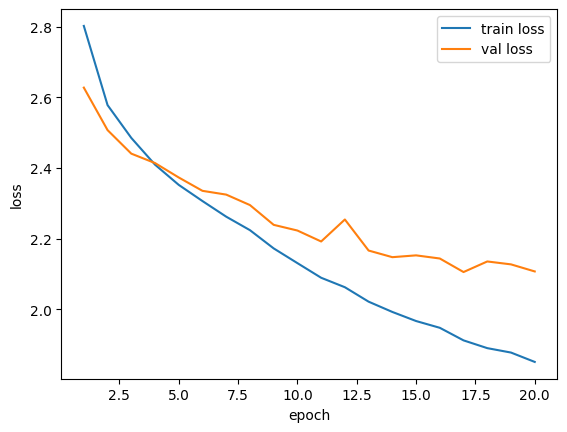

In [19]:
import matplotlib.pyplot as plt

ep, tr, va = zip(*lich_su)

plt.plot(ep, tr, label="train loss")
plt.plot(ep, va, label="val loss")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.legend()
plt.show()

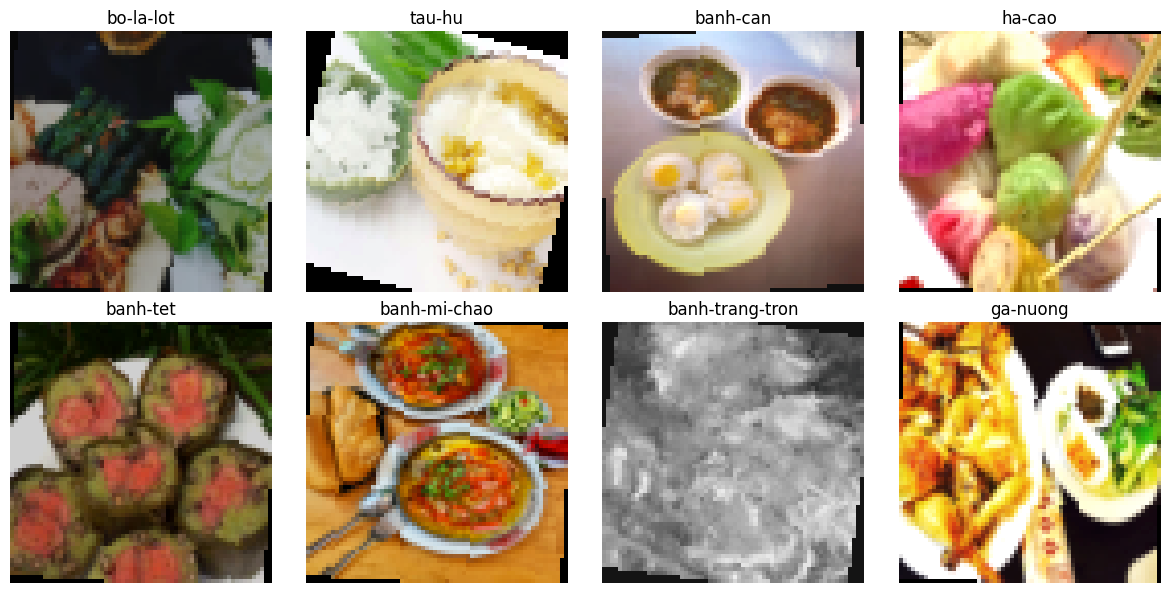

In [20]:
import matplotlib.pyplot as plt
import torch

# Lấy một batch ảnh đã qua train_tf
xb, yb = next(iter(train_dl))

# Đảo bước Normalize để hiển thị màu ảnh
mean = torch.tensor(MEAN).view(3, 1, 1)
std = torch.tensor(STD).view(3, 1, 1)

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    image = (xb[i].cpu() * std + mean).clamp(0, 1)
    ax.imshow(image.permute(1, 2, 0).numpy())
    ax.set_title(CLASSES[yb[i].item()])
    ax.axis("off")

plt.tight_layout()
plt.show()

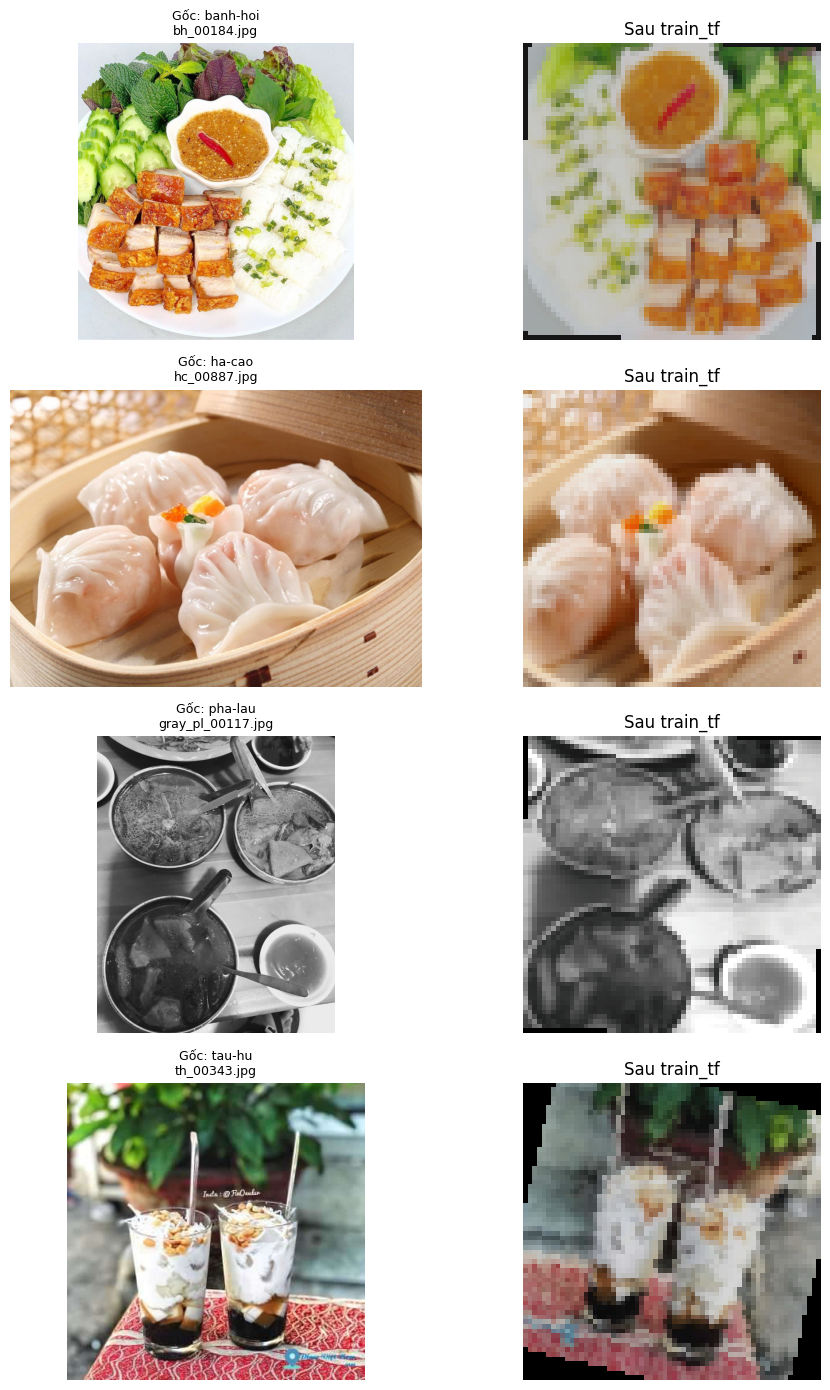

In [21]:
from PIL import Image
from pathlib import Path
import matplotlib.pyplot as plt
import torch

mean = torch.tensor(MEAN).view(3, 1, 1)
std = torch.tensor(STD).view(3, 1, 1)

fig, axes = plt.subplots(4, 2, figsize=(10, 14))

for row, index in enumerate(train_ds.indices[:4]):
    # Tìm đường dẫn và nhãn của cùng một ảnh
    path, label = train_ds.dataset.samples[index]

    with Image.open(path) as image:
        original = image.convert("RGB")

    # Áp dụng transform một lần để so sánh
    transformed = train_tf(original)
    displayed = (transformed * std + mean).clamp(0, 1)

    axes[row, 0].imshow(original)
    axes[row, 0].set_title(
        f"Gốc: {CLASSES[label]}\n{Path(path).name}",
        fontsize=9
    )

    axes[row, 1].imshow(displayed.permute(1, 2, 0).numpy())
    axes[row, 1].set_title("Sau train_tf")

    axes[row, 0].axis("off")
    axes[row, 1].axis("off")

plt.tight_layout()
plt.show()

In [22]:
from sklearn.metrics import classification_report

# Đánh giá bằng mô hình đã huấn luyện
val_loss, val_acc, y_true, y_pred = evaluate(
    model, val_dl, criterion, device
)

print(f"Validation accuracy: {val_acc:.2%}")

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(CLASSES))),
    target_names=CLASSES,
    digits=4,
    zero_division=0
))

Validation accuracy: 35.76%
                  precision    recall  f1-score   support

        banh-can     0.4667    0.1707    0.2500        41
        banh-hoi     0.2832    0.3516    0.3137        91
    banh-mi-chao     0.3250    0.4333    0.3714        30
        banh-tet     0.4921    0.6739    0.5688        46
 banh-trang-tron     0.3182    0.1489    0.2029        47
          banh-u     0.3333    0.0952    0.1481        21
        banh-uot     0.2411    0.4000    0.3009        85
       bap-nuong     0.6667    0.0714    0.1290        28
          bo-kho     0.2469    0.4255    0.3125        47
       bo-la-lot     0.5250    0.6087    0.5638        69
       bot-chien     0.2553    0.2791    0.2667        43
           ca-ri     0.4000    0.1538    0.2222        26
    canh-kho-qua     0.4400    0.5946    0.5057        37
   canh-khoai-mo     0.7667    0.8214    0.7931        28
        ga-nuong     0.3810    0.3636    0.3721        66
          goi-ga     0.4074    0.6346    0.

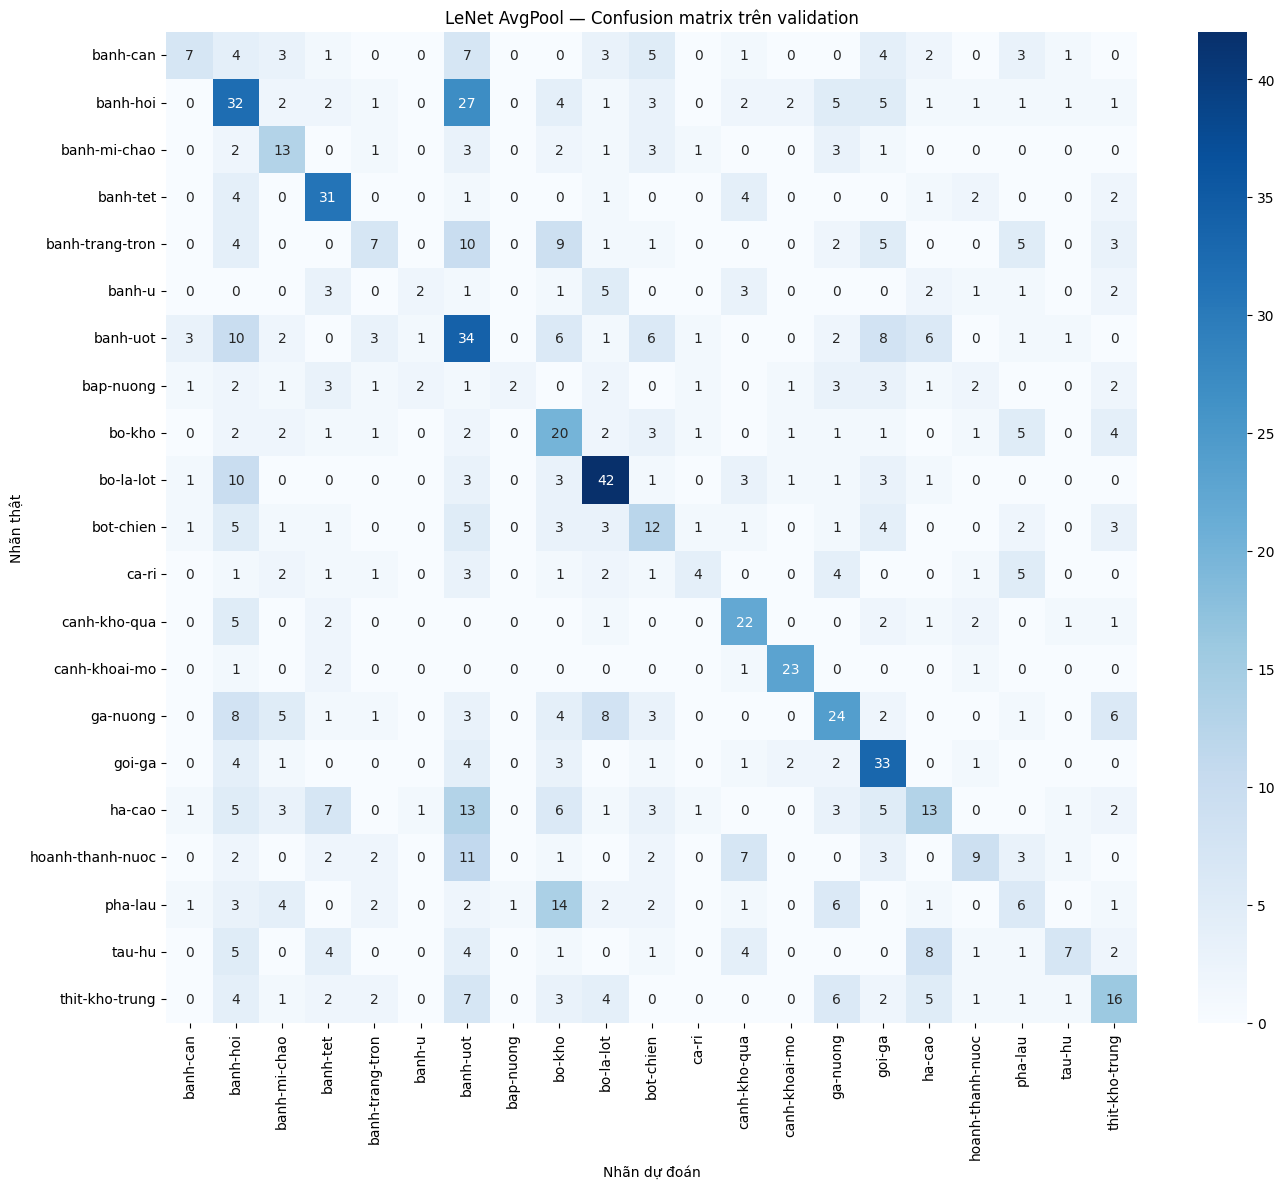

In [23]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(CLASSES)))
)

plt.figure(figsize=(14, 12))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASSES,
    yticklabels=CLASSES
)

plt.xlabel("Nhãn dự đoán")
plt.ylabel("Nhãn thật")
plt.title("LeNet AvgPool — Confusion matrix trên validation")
plt.tight_layout()
plt.show()

In [24]:
from pathlib import Path

save_dir = Path("outputs")
save_dir.mkdir(exist_ok=True)

torch.save({
    "model_state_dict": model.state_dict(),
    "pool": "avg",
    "img_size": IMG_SIZE,
    "classes": CLASSES,
    "seed": SEED,
    "epochs": EPOCHS,
    "history": lich_su,
    "val_accuracy": val_acc,
    "val_y_true": y_true,
    "val_y_pred": y_pred,
}, save_dir / "lenet_avgpool.pt")

print("Đã lưu:", (save_dir / "lenet_avgpool.pt").resolve())

Đã lưu: D:\Main class UIT\Năm 3\DS201_DeepLearning\TH\TH Buoi2\outputs\lenet_avgpool.pt


In [25]:
# Bản vừa huấn luyện: mặc định pool="avg"
model = LeNet5(in_ch=3, img=IMG_SIZE, num_classes=len(CLASSES))

# Bản tiếp theo
model = LeNet5(
    in_ch=3, img=IMG_SIZE, num_classes=len(CLASSES), pool="max"
)

In [26]:
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

lich_su_max = []

for ep in range(1, EPOCHS + 1):
    tr_loss, tr_acc = train_one_epoch(
        model, train_dl, criterion, optimizer, device
    )
    va_loss, va_acc, _, _ = evaluate(
        model, val_dl, criterion, device
    )

    lich_su_max.append((ep, tr_loss, va_loss))

    print(f"epoch {ep:>2}  train {tr_loss:.4f}/{tr_acc:.4f}"
          f"   val {va_loss:.4f}/{va_acc:.4f}")

epoch  1  train 2.7866/0.1497   val 2.6776/0.1823
epoch  2  train 2.5630/0.2216   val 2.4817/0.2311
epoch  3  train 2.4468/0.2501   val 2.3903/0.2400
epoch  4  train 2.3707/0.2665   val 2.3429/0.2948
epoch  5  train 2.3059/0.2874   val 2.2820/0.3088
epoch  6  train 2.2346/0.3145   val 2.2618/0.3177
epoch  7  train 2.1976/0.3235   val 2.2050/0.3297
epoch  8  train 2.1308/0.3455   val 2.1769/0.3466
epoch  9  train 2.0911/0.3640   val 2.1505/0.3446
epoch 10  train 2.0389/0.3689   val 2.1265/0.3685
epoch 11  train 2.0087/0.3791   val 2.1216/0.3705
epoch 12  train 1.9828/0.3862   val 2.0741/0.3855
epoch 13  train 1.9467/0.4015   val 2.0835/0.3655
epoch 14  train 1.9207/0.4095   val 2.0770/0.3745
epoch 15  train 1.9198/0.4138   val 2.0398/0.3914
epoch 16  train 1.8777/0.4155   val 2.0881/0.3934
epoch 17  train 1.8548/0.4231   val 2.0291/0.3775
epoch 18  train 1.8317/0.4303   val 2.0809/0.3845
epoch 19  train 1.8041/0.4409   val 2.1045/0.3536
epoch 20  train 1.7917/0.4440   val 2.0286/0.3805


In [27]:
from pathlib import Path

save_dir = Path("outputs")
save_dir.mkdir(exist_ok=True)

torch.save({
    "model_state_dict": model.state_dict(),
    "pool": "max",
    "img_size": IMG_SIZE,
    "classes": CLASSES,
    "seed": SEED,
    "epochs": EPOCHS,
    "history": lich_su_max,
    "val_accuracy": va_acc,
}, save_dir / "lenet_maxpool.pt")

print("Đã lưu:", (save_dir / "lenet_maxpool.pt").resolve())

Đã lưu: D:\Main class UIT\Năm 3\DS201_DeepLearning\TH\TH Buoi2\outputs\lenet_maxpool.pt


In [28]:
test_ds = datasets.ImageFolder(
    DATA_ROOT / "test",
    transform=eval_tf
)

assert test_ds.classes == CLASSES

test_dl = DataLoader(
    test_ds,
    batch_size=BATCH,
    shuffle=False,
    num_workers=2
)

print("Số ảnh test:", len(test_ds))

Số ảnh test: 6682


In [29]:
checkpoint_avg = torch.load(
    "outputs/lenet_avgpool.pt",
    map_location=device,
    weights_only=True
)

assert checkpoint_avg["classes"] == CLASSES
assert checkpoint_avg["pool"] == "avg"

model_avg = LeNet5(
    in_ch=3,
    img=IMG_SIZE,
    num_classes=len(CLASSES),
    pool="avg"
).to(device)

model_avg.load_state_dict(checkpoint_avg["model_state_dict"])

<All keys matched successfully>

In [30]:
import pandas as pd
from sklearn.metrics import classification_report

assert isinstance(model.s2, nn.MaxPool2d)

ket_qua_lenet = []
du_doan_lenet = {}

for name, net in [("AvgPool", model_avg), ("MaxPool", model)]:
    test_loss, test_acc, yt, yp = evaluate(
        net, test_dl, criterion, device
    )

    report = classification_report(
        yt, yp,
        labels=list(range(len(CLASSES))),
        target_names=CLASSES,
        output_dict=True,
        zero_division=0
    )

    print(f"\nLeNet {name} — Test")
    print(classification_report(
        yt, yp,
        labels=list(range(len(CLASSES))),
        target_names=CLASSES,
        digits=4,
        zero_division=0
    ))

    ket_qua_lenet.append({
        "Pooling": name,
        "Parameters": n_params(net),
        "Test loss": test_loss,
        "Accuracy": test_acc,
        "Precision macro": report["macro avg"]["precision"],
        "Recall macro": report["macro avg"]["recall"],
        "F1-macro": report["macro avg"]["f1-score"],
    })

    du_doan_lenet[name] = (yt, yp)

    pd.DataFrame(report).T.to_csv(
        f"outputs/lenet_{name.lower()}_test_report.csv"
    )

bang_so_sanh = pd.DataFrame(ket_qua_lenet)
bang_so_sanh.to_csv("outputs/lenet_comparison_test.csv", index=False)
display(bang_so_sanh)


LeNet AvgPool — Test
                  precision    recall  f1-score   support

        banh-can     0.1918    0.0581    0.0892       241
        banh-hoi     0.3192    0.3591    0.3380       607
    banh-mi-chao     0.3123    0.2734    0.2915       289
        banh-tet     0.3456    0.3352    0.3403       364
 banh-trang-tron     0.2548    0.1715    0.2050       309
          banh-u     0.3614    0.1705    0.2317       176
        banh-uot     0.2563    0.4161    0.3172       560
       bap-nuong     0.3333    0.0350    0.0633       143
          bo-kho     0.2840    0.4083    0.3350       338
       bo-la-lot     0.4383    0.5197    0.4755       458
       bot-chien     0.2023    0.2536    0.2251       276
           ca-ri     0.2500    0.0760    0.1166       171
    canh-kho-qua     0.3592    0.5103    0.4217       290
   canh-khoai-mo     0.6140    0.7071    0.6573       198
        ga-nuong     0.2707    0.1935    0.2257       372
          goi-ga     0.1739    0.3448    0.2312  

,Pooling,Parameters,Test loss,Accuracy,Precision macro,Recall macro,F1-macro
0,AvgPool,339421,2.319141,0.303352,0.311712,0.282996,0.278608
1,MaxPool,339421,2.205580,0.331637,0.341475,0.316889,0.315782


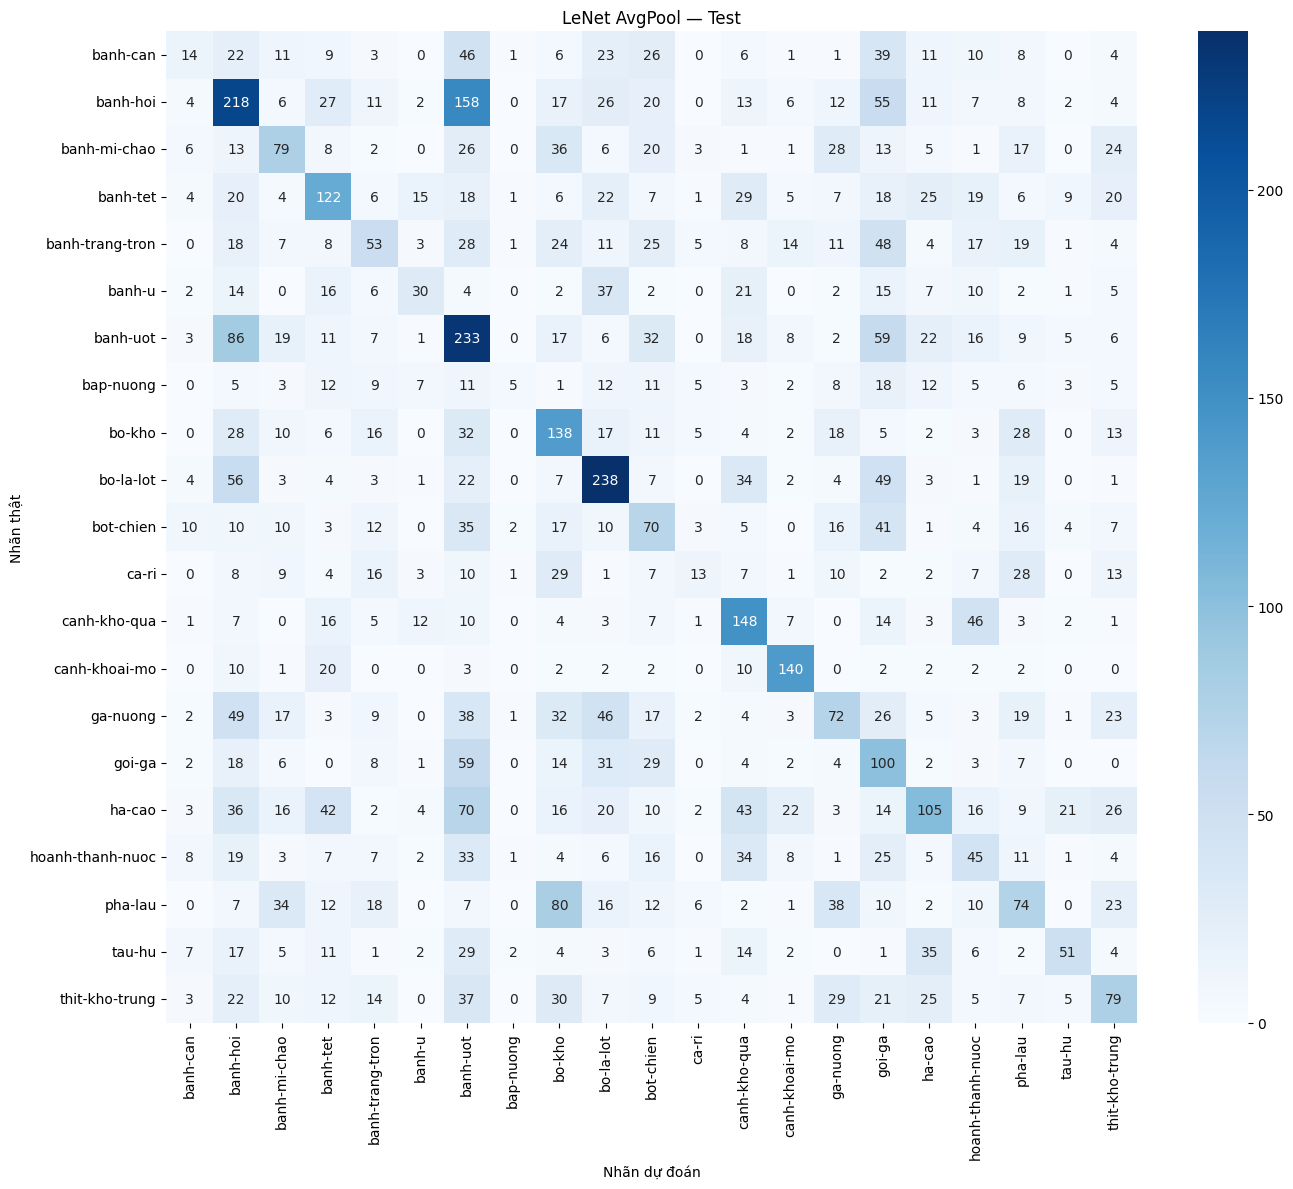

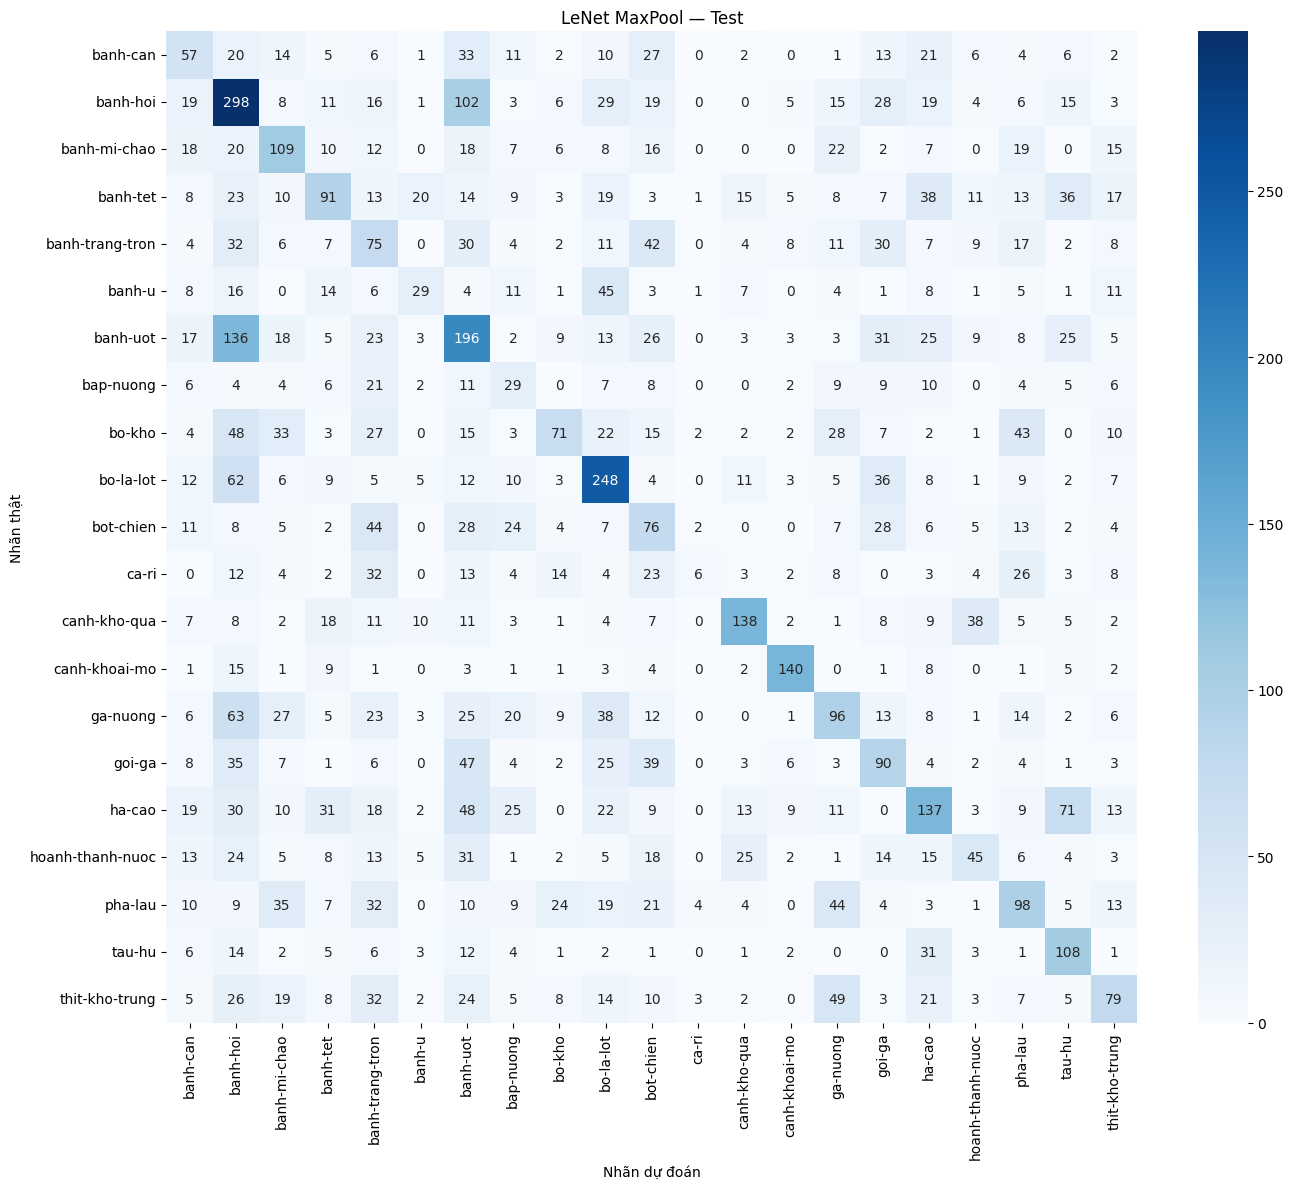

In [31]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

for name, (yt, yp) in du_doan_lenet.items():
    cm = confusion_matrix(
        yt, yp,
        labels=list(range(len(CLASSES)))
    )

    plt.figure(figsize=(14, 12))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=CLASSES,
        yticklabels=CLASSES
    )

    plt.xlabel("Nhãn dự đoán")
    plt.ylabel("Nhãn thật")
    plt.title(f"LeNet {name} — Test")
    plt.tight_layout()
    plt.savefig(
        f"outputs/lenet_{name.lower()}_test_cm.png",
        dpi=150
    )
    plt.show()

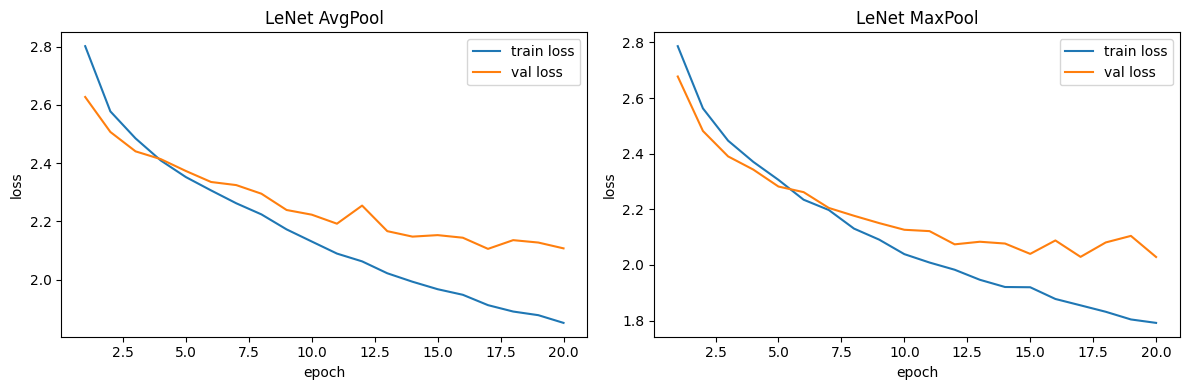

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, name, history in [
    (axes[0], "AvgPool", checkpoint_avg["history"]),
    (axes[1], "MaxPool", lich_su_max),
]:
    ep, tr, va = zip(*history)
    ax.plot(ep, tr, label="train loss")
    ax.plot(ep, va, label="val loss")
    ax.set_title(f"LeNet {name}")
    ax.set_xlabel("epoch")
    ax.set_ylabel("loss")
    ax.legend()

plt.tight_layout()
plt.savefig("outputs/lenet_loss_comparison.png", dpi=150)
plt.show()

### Bài 2: Xây dựng mô hình GoogLeNet. Huấn luyện và đánh giá mô hình GoogLeNet trên 4 độ đo precision, recall và F1 (sử dụng Adam làm optimizer).

**Inception Blocks**

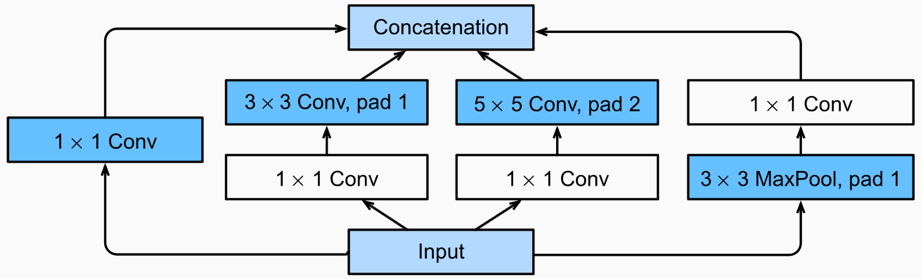

**GoogLeNet (Multi-branch Network)**

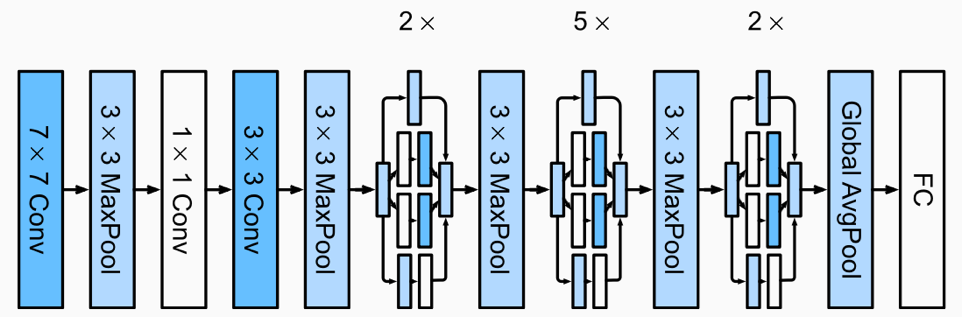

In [33]:
class InceptionBlock(nn.Module):
    def __init__(self, in_ch, f1, f3r, f3, f5r, f5, fp):
        super().__init__()

        self.b1 = nn.Sequential(
            nn.Conv2d(in_ch, f1, 1),
            nn.ReLU()
        )

        self.b2 = nn.Sequential(
            nn.Conv2d(in_ch, f3r, 1),
            nn.ReLU(),
            nn.Conv2d(f3r, f3, 3, padding=1),
            nn.ReLU()
        )

        self.b3 = nn.Sequential(
            nn.Conv2d(in_ch, f5r, 1),
            nn.ReLU(),
            nn.Conv2d(f5r, f5, 5, padding=2),
            nn.ReLU()
        )

        self.b4 = nn.Sequential(
            nn.MaxPool2d(3, stride=1, padding=1),
            nn.Conv2d(in_ch, fp, 1),
            nn.ReLU()
        )

    def forward(self, x):
        return torch.cat([
            self.b1(x),
            self.b2(x),
            self.b3(x),
            self.b4(x)
        ], dim=1)

In [34]:
class GoogLeNet(nn.Module):
    def __init__(self, num_classes=21):
        super().__init__()

        self.inc1 = InceptionBlock(
            3, 16, 16, 24, 4, 8, 8
        )  # 16 + 24 + 8 + 8 = 56 channel

        self.inc2 = InceptionBlock(
            56, 32, 32, 48, 8, 16, 16
        )  # 32 + 48 + 16 + 16 = 112 channel

        self.inc3 = InceptionBlock(
            112, 64, 48, 64, 8, 16, 32
        )  # 64 + 64 + 16 + 32 = 176 channel

        self.pool = nn.MaxPool2d(2, 2)
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(176, num_classes)

    def forward(self, x):
        x = self.pool(self.inc1(x))
        x = self.pool(self.inc2(x))
        x = self.inc3(x)
        x = self.gap(x)
        x = x.flatten(1)
        return self.fc(x)

In [35]:
googlenet = GoogLeNet(num_classes=len(CLASSES))

x = torch.zeros(1, 3, IMG_SIZE, IMG_SIZE)

with torch.no_grad():
    x = googlenet.inc1(x)
    print("Inception 1:", tuple(x.shape))
    assert x.shape[1] == 56

    x = googlenet.pool(x)
    x = googlenet.inc2(x)
    print("Inception 2:", tuple(x.shape))
    assert x.shape[1] == 112

    x = googlenet.pool(x)
    x = googlenet.inc3(x)
    print("Inception 3:", tuple(x.shape))
    assert x.shape[1] == 176

    x = googlenet.gap(x).flatten(1)
    logits = googlenet.fc(x)
    print("Đầu ra:", tuple(logits.shape))
    assert logits.shape == (1, 21)

print("Số tham số:", f"{n_params(googlenet):,}")

Inception 1: (1, 56, 64, 64)
Inception 2: (1, 112, 32, 32)
Inception 3: (1, 176, 16, 16)
Đầu ra: (1, 21)
Số tham số: 78,389


In [36]:
import time
from pathlib import Path

save_dir = Path("outputs")
save_dir.mkdir(exist_ok=True)

googlenet = googlenet.to(device)

criterion_googlenet = nn.CrossEntropyLoss()
optimizer_googlenet = torch.optim.Adam(
    googlenet.parameters(), lr=1e-3
)

lich_su_googlenet = []
thoi_gian_googlenet = []

for ep in range(1, EPOCHS + 1):
    if device.type == "cuda":
        torch.cuda.synchronize()
    start = time.perf_counter()

    tr_loss, tr_acc = train_one_epoch(
        googlenet, train_dl, criterion_googlenet,
        optimizer_googlenet, device
    )
    va_loss, va_acc, _, _ = evaluate(
        googlenet, val_dl, criterion_googlenet, device
    )

    if device.type == "cuda":
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - start

    lich_su_googlenet.append((ep, tr_loss, va_loss))
    thoi_gian_googlenet.append(elapsed)

    torch.save({
        "model_state_dict": googlenet.state_dict(),
        "img_size": IMG_SIZE,
        "classes": CLASSES,
        "seed": SEED,
        "epoch": ep,
        "history": lich_su_googlenet,
        "seconds_per_epoch": thoi_gian_googlenet,
    }, save_dir / "googlenet.pt")

    print(f"epoch {ep:>2}  train {tr_loss:.4f}/{tr_acc:.4f}"
          f"   val {va_loss:.4f}/{va_acc:.4f}"
          f"   {elapsed:.1f}s")

epoch  1  train 2.8627/0.1284   val 2.7364/0.1604   145.1s
epoch  2  train 2.6043/0.1989   val 2.5681/0.2012   146.8s
epoch  3  train 2.4686/0.2358   val 2.4349/0.2610   159.4s
epoch  4  train 2.3821/0.2623   val 2.3554/0.2839   150.8s
epoch  5  train 2.2982/0.2860   val 2.3115/0.3008   147.4s
epoch  6  train 2.2388/0.3074   val 2.2517/0.3337   143.6s
epoch  7  train 2.1809/0.3213   val 2.2027/0.3367   138.1s
epoch  8  train 2.1448/0.3320   val 2.1583/0.3436   134.2s
epoch  9  train 2.0892/0.3512   val 2.1714/0.3297   135.9s
epoch 10  train 2.0657/0.3576   val 2.0644/0.3675   142.2s
epoch 11  train 2.0169/0.3744   val 2.1065/0.3486   137.6s
epoch 12  train 1.9957/0.3817   val 2.0206/0.3825   133.1s
epoch 13  train 1.9621/0.3876   val 2.0335/0.3755   132.3s
epoch 14  train 1.9450/0.3929   val 2.0471/0.3556   140.0s
epoch 15  train 1.9102/0.4072   val 1.9695/0.3815   148.2s
epoch 16  train 1.8871/0.4148   val 1.9527/0.3974   160.5s
epoch 17  train 1.8664/0.4227   val 1.9326/0.3984   147.

In [37]:
from sklearn.metrics import classification_report

test_loss_google, test_acc_google, y_true_google, y_pred_google = evaluate(
    googlenet, test_dl, criterion_googlenet, device
)

report_google = classification_report(
    y_true_google,
    y_pred_google,
    labels=list(range(len(CLASSES))),
    target_names=CLASSES,
    output_dict=True,
    zero_division=0
)

print(f"Test loss: {test_loss_google:.4f}")
print(f"Test accuracy: {test_acc_google:.2%}")

print(classification_report(
    y_true_google,
    y_pred_google,
    labels=list(range(len(CLASSES))),
    target_names=CLASSES,
    digits=4,
    zero_division=0
))

pd.DataFrame(report_google).T.to_csv(
    "outputs/googlenet_test_report.csv"
)

Test loss: 2.0726
Test accuracy: 36.52%
                  precision    recall  f1-score   support

        banh-can     0.2629    0.2531    0.2579       241
        banh-hoi     0.3210    0.6161    0.4221       607
    banh-mi-chao     0.3273    0.5017    0.3962       289
        banh-tet     0.3388    0.5082    0.4066       364
 banh-trang-tron     0.3853    0.1359    0.2010       309
          banh-u     0.6000    0.1534    0.2443       176
        banh-uot     0.3424    0.3357    0.3390       560
       bap-nuong     0.3947    0.1049    0.1657       143
          bo-kho     0.3555    0.4438    0.3947       338
       bo-la-lot     0.6083    0.5764    0.5919       458
       bot-chien     0.4521    0.1196    0.1891       276
           ca-ri     0.3200    0.1871    0.2362       171
    canh-kho-qua     0.4586    0.6310    0.5312       290
   canh-khoai-mo     0.8543    0.6515    0.7393       198
        ga-nuong     0.3578    0.2231    0.2748       372
          goi-ga     0.4318    

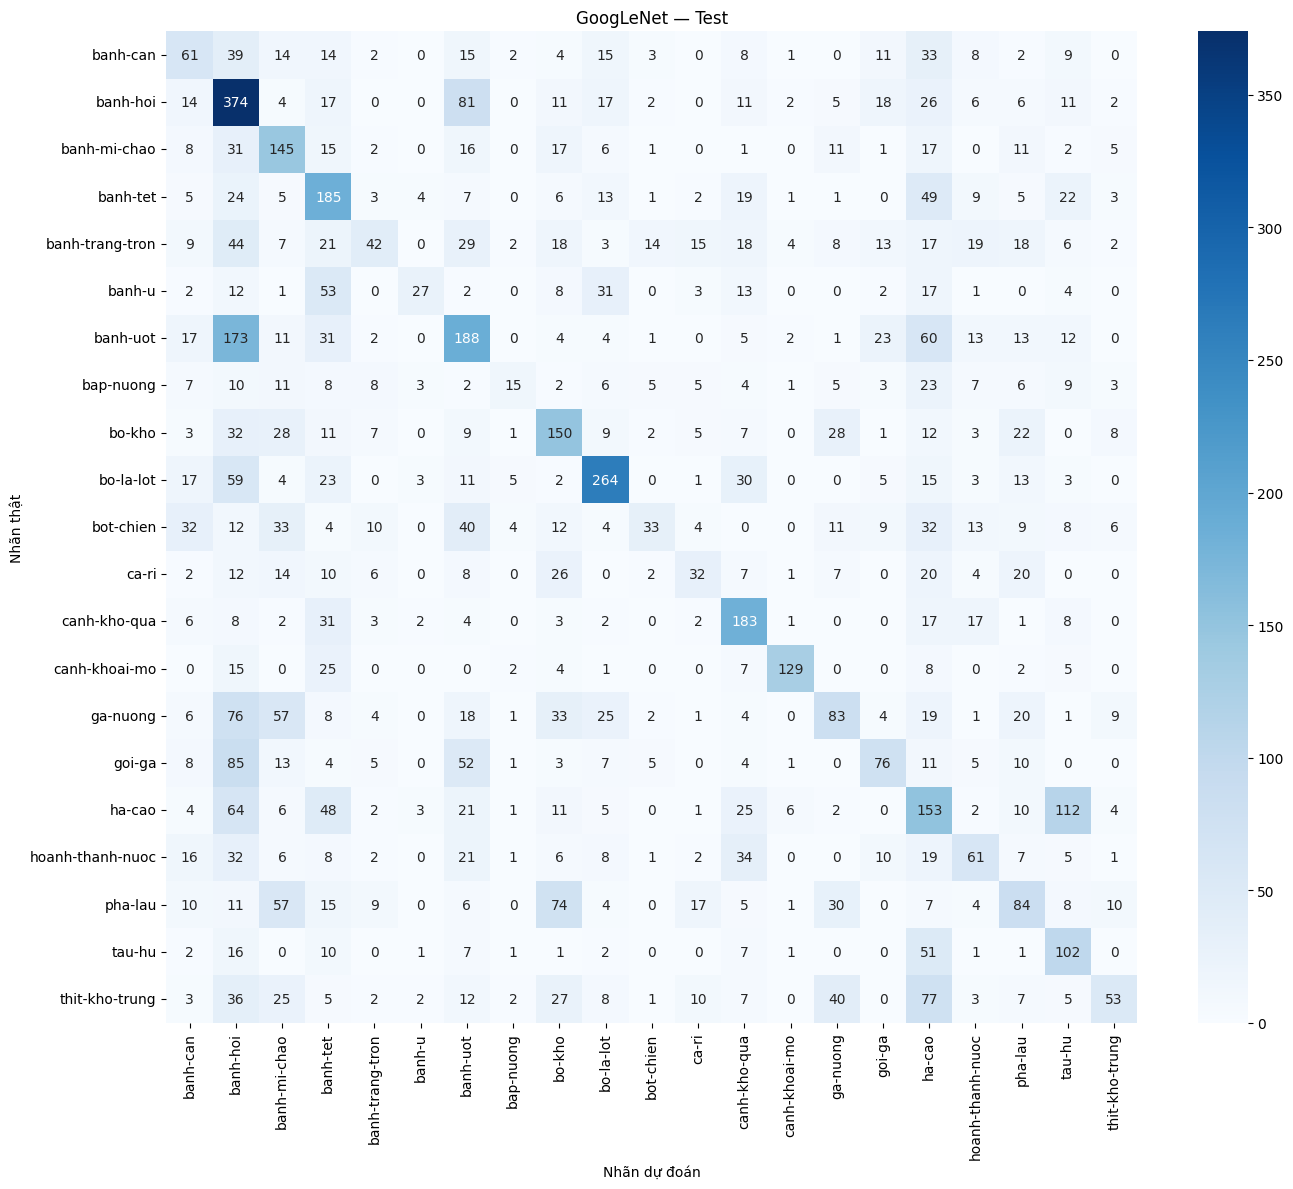

In [38]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm_google = confusion_matrix(
    y_true_google,
    y_pred_google,
    labels=list(range(len(CLASSES)))
)

plt.figure(figsize=(14, 12))
sns.heatmap(
    cm_google,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASSES,
    yticklabels=CLASSES
)

plt.xlabel("Nhãn dự đoán")
plt.ylabel("Nhãn thật")
plt.title("GoogLeNet — Test")
plt.tight_layout()
plt.savefig("outputs/googlenet_test_cm.png", dpi=150)
plt.show()

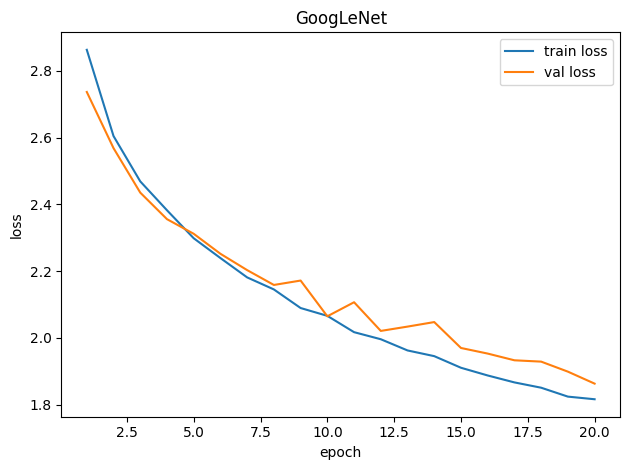

In [39]:
import matplotlib.pyplot as plt
import pandas as pd

ep, tr, va = zip(*lich_su_googlenet)

plt.plot(ep, tr, label="train loss")
plt.plot(ep, va, label="val loss")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.title("GoogLeNet")
plt.legend()
plt.tight_layout()
plt.savefig("outputs/googlenet_loss.png", dpi=150)
plt.show()


### Thời gian thực thi

Đo bổ sung một epoch train và validation cho mỗi mô hình trên cùng máy, batch 32, num_workers=2. Dùng bản sao từ checkpoint nên không thay đổi các trọng số đã dùng đánh giá test. Thời gian không bao gồm khởi tạo mô hình, đọc checkpoint và lưu file. Cột này là số đo một epoch bổ sung, không phải trung bình của 20 epoch cũ.


In [ ]:
import time
import random
from pathlib import Path
import numpy as np
import pandas as pd

timing_path = Path("outputs/epoch_timing_supplement.csv")

if not timing_path.exists():
    timing_rows = []
    configs_timing = [
        ("LeNet AvgPool", "lenet_avgpool.pt", lambda: LeNet5(pool="avg")),
        ("LeNet MaxPool", "lenet_maxpool.pt", lambda: LeNet5(pool="max")),
        ("GoogLeNet", "googlenet.pt", lambda: GoogLeNet(num_classes=len(CLASSES))),
    ]

    for name, checkpoint_file, factory in configs_timing:
        torch.manual_seed(SEED)
        random.seed(SEED)
        np.random.seed(SEED)
        train_timing = DataLoader(
            train_ds, batch_size=BATCH, shuffle=True, num_workers=2,
            generator=torch.Generator().manual_seed(SEED)
        )
        val_timing = DataLoader(
            val_ds, batch_size=BATCH, shuffle=False, num_workers=2
        )
        net_timing = factory().to(device)
        ck_timing = torch.load(
            Path("outputs") / checkpoint_file,
            map_location=device, weights_only=True
        )
        assert ck_timing["classes"] == CLASSES
        net_timing.load_state_dict(ck_timing["model_state_dict"])
        loss_timing = nn.CrossEntropyLoss()
        opt_timing = torch.optim.Adam(net_timing.parameters(), lr=1e-3)

        if device.type == "cuda":
            torch.cuda.synchronize()
        start_timing = time.perf_counter()
        train_one_epoch(net_timing, train_timing, loss_timing, opt_timing, device)
        evaluate(net_timing, val_timing, loss_timing, device)
        if device.type == "cuda":
            torch.cuda.synchronize()
        seconds_timing = time.perf_counter() - start_timing

        timing_rows.append({
            "model": name,
            "seconds_per_epoch": seconds_timing,
            "measured_epochs": 1,
            "scope": "train_and_validation_excluding_checkpoint",
            "device": str(device),
            "torch_version": str(torch.__version__),
            "batch_size": BATCH,
            "num_workers": 2,
            "threads": torch.get_num_threads(),
        })
        del net_timing, opt_timing, train_timing, val_timing
        if device.type == "cuda":
            torch.cuda.empty_cache()

    pd.DataFrame(timing_rows).to_csv(timing_path, index=False)

bang_thoi_gian = pd.read_csv(timing_path)
display(bang_thoi_gian[["model", "seconds_per_epoch", "measured_epochs", "device", "batch_size"]])


model,seconds_per_epoch,measured_epochs,device,batch_size
LeNet AvgPool,127.588280,1,cpu,32
LeNet MaxPool,130.086826,1,cpu,32
GoogLeNet,145.378292,1,cpu,32


### Số channel của các Inception block

| Block | Channel vào | Tính channel ra | Channel ra |
|---|---:|---|---:|
| Inception 1 | 3 | 16 + 24 + 8 + 8 | 56 |
| Inception 2 | 56 | 32 + 48 + 16 + 16 | 112 |
| Inception 3 | 112 | 64 + 64 + 16 + 32 | 176 |

Channel ra là tổng channel cuối của bốn nhánh. Channel của các lớp 1×1 trung gian không cộng vào kết quả này. Các giá trị khớp với shape đã in khi kiểm tra mô hình.


In [ ]:
bang_tham_so_google = pd.DataFrame([
    {"Layer": name, "Parameters": n_params(layer)}
    for name, layer in [
        ("Inception 1", googlenet.inc1),
        ("Inception 2", googlenet.inc2),
        ("Inception 3", googlenet.inc3),
        ("MaxPool / GAP", googlenet.pool),
        ("Linear(176, 21)", googlenet.fc),
    ]
])
assert bang_tham_so_google["Parameters"].sum() == n_params(googlenet)
display(bang_tham_so_google)


Layer,Parameters
Inception 1,4464
Inception 2,22104
Inception 3,48104
MaxPool / GAP,0
"Linear(176, 21)",3717


### So sánh kết quả trên tập test

In [ ]:
bang_tong_hop = pd.read_csv("outputs/lenet_comparison_test.csv")
bang_tong_hop = bang_tong_hop.rename(columns={"Pooling": "Mô hình"})
bang_tong_hop["Mô hình"] = "LeNet " + bang_tong_hop["Mô hình"]

google_report = pd.read_csv("outputs/googlenet_test_report.csv", index_col=0)
google_checkpoint = torch.load("outputs/googlenet.pt", map_location="cpu", weights_only=True)
google_params = sum(t.numel() for t in google_checkpoint["model_state_dict"].values())
google_row = pd.DataFrame([{
    "Mô hình": "GoogLeNet",
    "Parameters": google_params,
    "Test loss": test_loss_google,
    "Accuracy": float(google_report.loc["accuracy", "precision"]),
    "Precision macro": float(google_report.loc["macro avg", "precision"]),
    "Recall macro": float(google_report.loc["macro avg", "recall"]),
    "F1-macro": float(google_report.loc["macro avg", "f1-score"]),
}])

bang_tong_hop = pd.concat([bang_tong_hop, google_row], ignore_index=True)
bang_tong_hop["Resize"] = "64x64"
bang_tong_hop["Giây/epoch"] = bang_tong_hop["Mô hình"].map(
    bang_thoi_gian.set_index("model")["seconds_per_epoch"]
)
bang_tong_hop = bang_tong_hop[[
    "Mô hình", "Resize", "Parameters", "Test loss", "Accuracy",
    "Precision macro", "Recall macro", "F1-macro", "Giây/epoch"
]]
display(bang_tong_hop)
bang_tong_hop.to_csv("outputs/lenet_googlenet_comparison.csv", index=False)


Mô hình,Resize,Parameters,Test loss,Accuracy,Precision macro,Recall macro,F1-macro,Giây/epoch
LeNet AvgPool,64x64,339421,2.319141,0.303352,0.311712,0.282996,0.278608,127.588280
LeNet MaxPool,64x64,339421,2.205580,0.331637,0.341475,0.316889,0.315782,130.086826
GoogLeNet,64x64,78389,2.072558,0.365160,0.404556,0.341948,0.341360,145.378292


### Nhận xét

MaxPool đạt accuracy 33,16% và macro-F1 31,58%, cao hơn AvgPool lần lượt 2,83 và 3,72 điểm phần trăm. Hai bản LeNet có cùng 339.421 tham số.

GoogLeNet rút gọn đạt accuracy 36,52% và macro-F1 34,14%, cao hơn LeNet MaxPool lần lượt 3,35 và 2,56 điểm phần trăm. Mô hình có 78.389 tham số, khoảng 23,1% số tham số của LeNet. Cả hai kiến trúc dùng ảnh 64×64 và cùng phép chia dữ liệu. Thời gian được so sánh bằng phép đo bổ sung ở trên; số tham số nhỏ hơn không đồng nghĩa số phép tính nhỏ hơn.

Train loss của cả ba mô hình giảm qua các epoch; validation loss giảm chậm hơn và có dao động. Chưa có xu hướng validation loss tăng kéo dài để xác định rõ epoch bắt đầu overfitting. Các kết quả so sánh lấy từ một lần huấn luyện mỗi cấu hình.


### Bài 3*: Xây dựng mô hình ResNet-18, đánh giá mô hình ResNet-18 trên bộ dữ liệu VinaFood21 sử dụng các độ đo precision, recall, và F1 (Sử dụng Adam làm optimizer).

**ResNet Block**

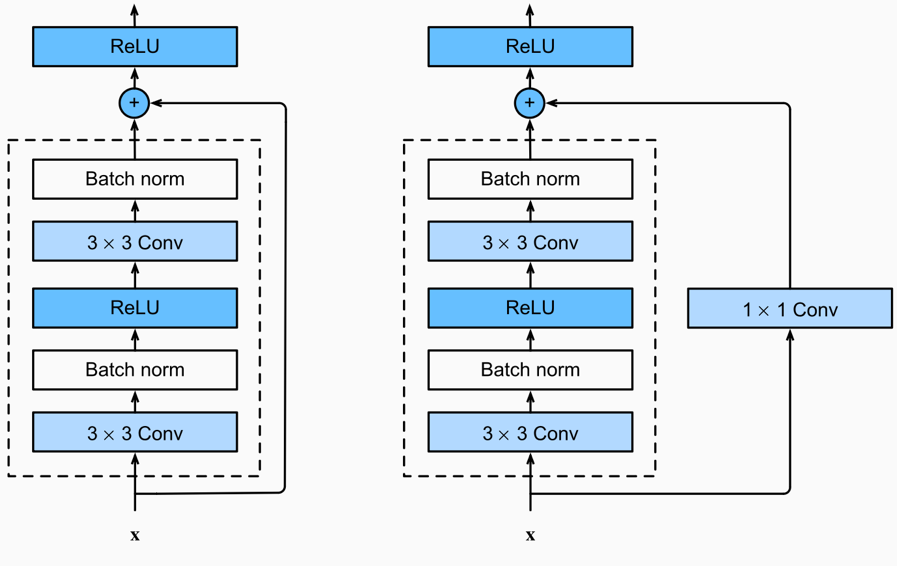

**ResNet**

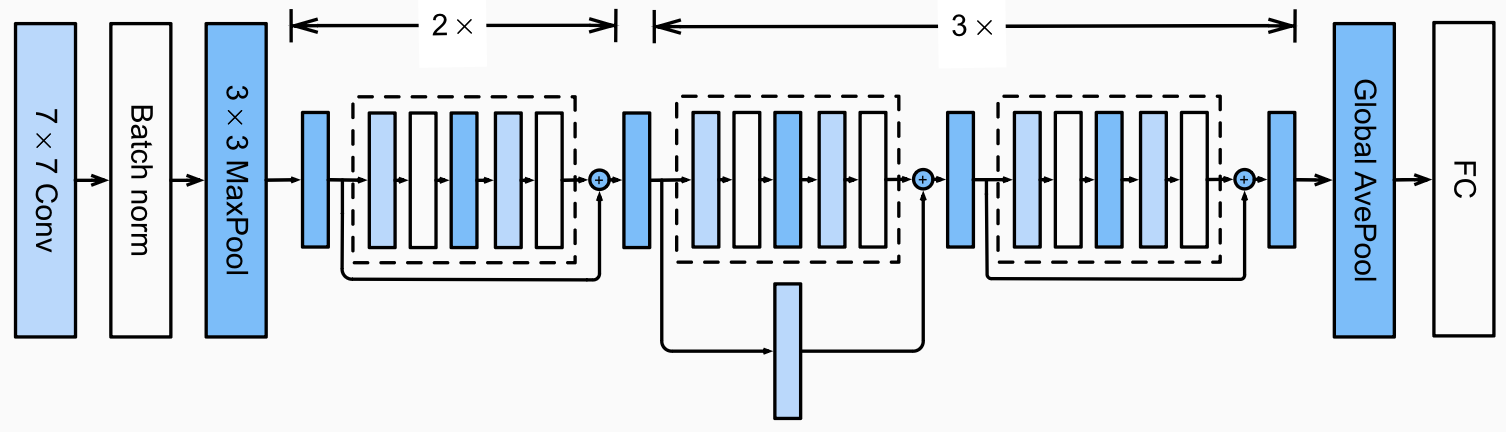

### Bài 4*: Sử dụng pretrained ResNet50 từ HuggingFace để fine-tune trên bộ dữ liệu VinaFood21.